ECG signal-এ আমরা P wave, QRS complex এবং T wave-এর মতো cardiac electrical activity-র বিভিন্ন অংশ দেখতে পাই। কিন্তু recording-এর সময় signal-এর baseline ধীরে ধীরে ওপরে-নিচে সরে যেতে পারে। একে baseline wander বলা হয়

Think Like this in a Easy Way:
- Clean ECG: waveform-এর baseline তুলনামূলকভাবে স্থির।
- Baseline-wander-affected ECG: heartbeat-এর waveform-এর সঙ্গে baseline-ও ধীরে ধীরে ওঠানামা করে।
- আমাদের লক্ষ্য: baseline-এর ধীর পরিবর্তন কমানো, কিন্তু গুরুত্বপূর্ণ cardiac waveform যতটা সম্ভব অক্ষত রাখা।

**Dataset load and making segment**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.datasets import electrocardiogram
from scipy.ndimage import uniform_filter1d

# Load the ECG signal
ecg = electrocardiogram()

# Sampling frequency
fs = 360  # samples per second (Hz)

# Select a 5-second segment
start_time = 5
end_time = 10

start_index = int(start_time * fs)
end_index = int(end_time * fs)

segment = ecg[start_index:end_index]

# Create the time axis for this segment
segment_time = np.arange(start_index, end_index) / fs

print("Segment samples:", len(segment))
print("Segment duration:", len(segment) / fs, "seconds")

Segment samples: 1800
Segment duration: 5.0 seconds


**Raw ECG Plotting**

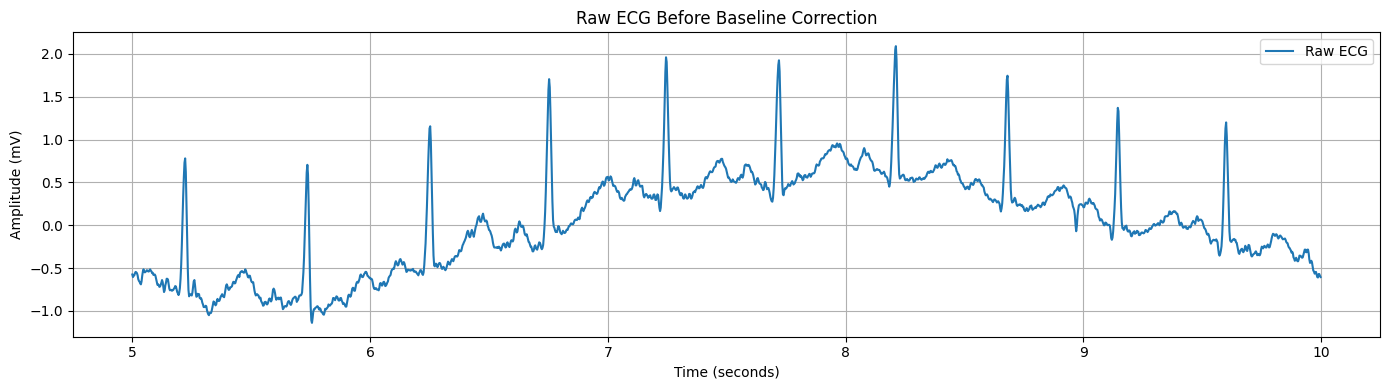

In [2]:
plt.figure(figsize=(14, 4))

plt.plot(segment_time, segment, label="Raw ECG")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Raw ECG Before Baseline Correction")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

let's understand the main concept.
Suppose we represent the ECG signal as follows:
\[
x(t)=s(t)+b(t)+n(t)
\]

Where:
- \(x(t)\) = Recorded ECG signal
- \(s(t)\) = Original cardiac signal
- \(b(t)\) = Baseline wander
- \(n(t)\) = Other noise
Our goal is to estimate the baseline wander \(b(t)\) and then subtract it from the raw signal to obtain a corrected ECG signal.
\[
y(t)=x(t)-\widehat{b}(t)
\]

Here, \(\widehat{b}(t)\) represents the estimated baseline, and \(y(t)\) represents the baseline-corrected ECG signal.
Important: A moving average does not perfectly separate baseline wander from the original ECG signal. It is a simple educational method, and choosing an inappropriate window size may also distort the original ECG waveform.

**Determine Window Size**

Window বলতে বোঝায়, একটি sample-এর আশেপাশের কতগুলো sample ব্যবহার করে local average তৈরি করা হবে।

In [3]:
window_seconds = 0.8

window_samples = int(window_seconds * fs)

print("Window duration:", window_seconds, "seconds")
print("Window size:", window_samples, "samples")

Window duration: 0.8 seconds
Window size: 288 samples


**Estimated Baseline Making**

In [5]:
estimated_baseline = uniform_filter1d(
    segment,
    size=window_samples,
    mode="reflect"
)

### Understanding Each Argument

| Argument | Meaning |
|---|---|
| `segment` | The ECG signal that we want to process. |
| `size=window_samples` | Specifies the moving-average window size of 288 samples. |
| `mode="reflect"` | Reflects the signal values at both edges to help the filter operate near the boundaries. |

The `uniform_filter1d()` function calculates the local average of neighboring samples at each position and returns an array with the same length as the input signal.

**Note:** `estimated_baseline` is not the raw ECG signal. Instead, it represents an estimate of the slow variations in the raw signal that may correspond to baseline wander.

**Raw signal থেকে estimated baseline বাদ দাও**

In [7]:
corrected_ecg = segment - estimated_baseline

### Baseline Correction

This is the key step in baseline correction.

Suppose, for a particular sample:

- **Raw amplitude:** 0.80 mV
- **Estimated baseline:** 0.25 mV

Then,

\[
0.80-0.25=0.55\text{ mV}
\]

Therefore, the corrected amplitude will be **0.55 mV**.

In a real ECG signal, this calculation is performed independently for every sample by subtracting the estimated baseline from the corresponding raw signal value.

**Visualize the raw ECG signal, the estimated baseline, and the baseline-corrected ECG signal in the same plot.**

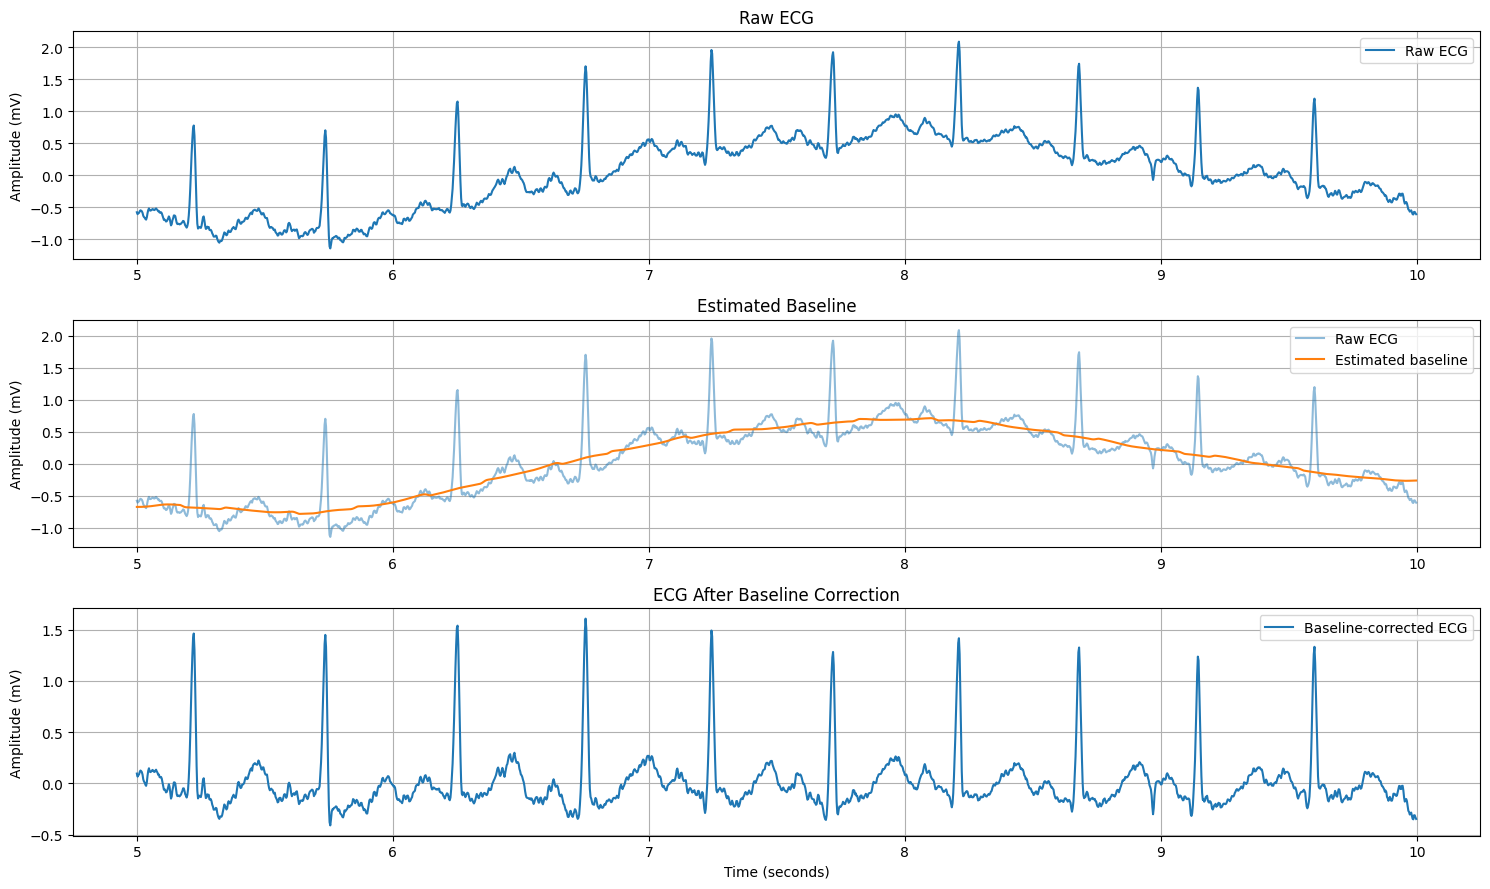

In [8]:
plt.figure(figsize=(15, 9))

# Plot 1: Raw ECG
plt.subplot(3, 1, 1)
plt.plot(segment_time, segment, label="Raw ECG")
plt.ylabel("Amplitude (mV)")
plt.title("Raw ECG")
plt.legend()
plt.grid(True)

# Plot 2: Estimated baseline
plt.subplot(3, 1, 2)
plt.plot(segment_time, segment, label="Raw ECG", alpha=0.5)
plt.plot(
    segment_time,
    estimated_baseline,
    label="Estimated baseline"
)
plt.ylabel("Amplitude (mV)")
plt.title("Estimated Baseline")
plt.legend()
plt.grid(True)

# Plot 3: Corrected ECG
plt.subplot(3, 1, 3)
plt.plot(
    segment_time,
    corrected_ecg,
    label="Baseline-corrected ECG"
)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("ECG After Baseline Correction")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Filtering-এর আগে ও পরে numerical comparison**

In [9]:
print("RAW ECG")
print("Mean:", np.mean(segment))
print("Standard deviation:", np.std(segment))

print("\nCORRECTED ECG")
print("Mean:", np.mean(corrected_ecg))
print("Standard deviation:", np.std(corrected_ecg))

RAW ECG
Mean: 0.03503055555555557
Standard deviation: 0.5762363873154471

CORRECTED ECG
Mean: 0.00011459297839440255
Standard deviation: 0.26665976992500917


**For the Better Visualization**

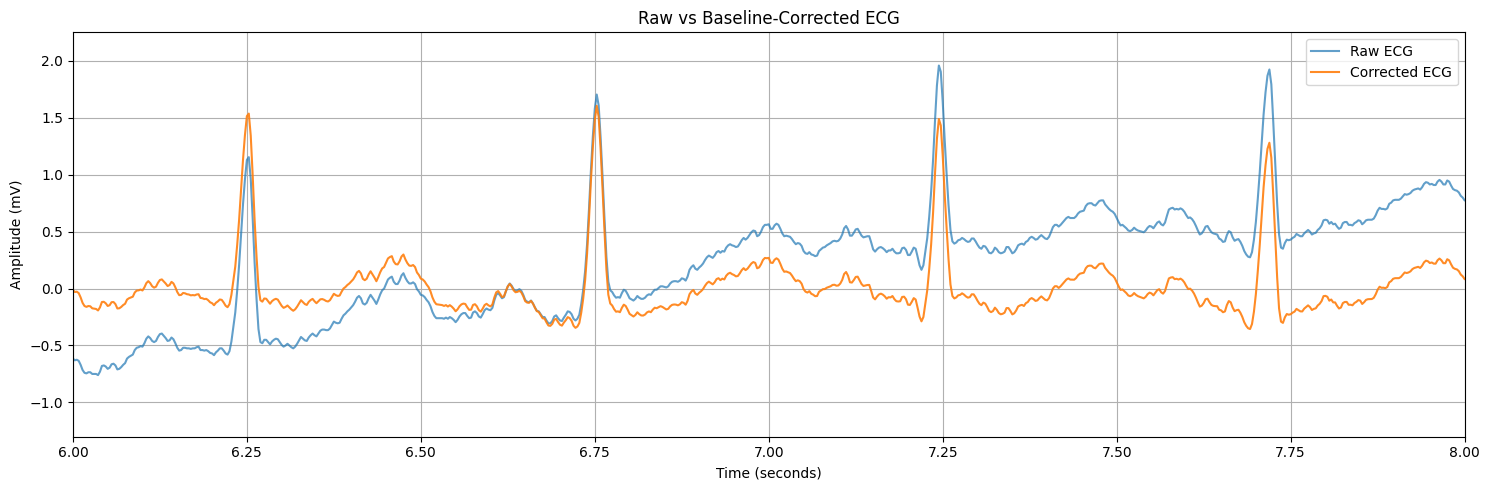

In [10]:
plt.figure(figsize=(15, 5))

plt.plot(
    segment_time,
    segment,
    label="Raw ECG",
    alpha=0.7
)

plt.plot(
    segment_time,
    corrected_ecg,
    label="Corrected ECG",
    alpha=0.9
)

plt.xlim(6, 8)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Raw vs Baseline-Corrected ECG")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()